# BERT Fine-Tuning Baseline

In [1]:
from contextlib import redirect_stdout
from functools import partial
from io import StringIO
from pathlib import Path

import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from bert_data import BertReviewDataset, collate_bert_reviews
from utils import get_device
from train import train_model, evaluate
from utils import plot_history


c:\Users\99243\miniconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Pretrained Tokenizer

In [2]:
MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


## Dataloader

In [3]:
DATA_DIR = "data/merged"
GENRE = "FPS"
batch_size = 64

torch.manual_seed(42)

data_dir = Path(DATA_DIR)

collate_fn = partial(
    collate_bert_reviews,
    tokenizer=tokenizer,
    max_length=256
)

loaders = {}

for split in ("train", "val", "test"):
    df = pd.read_csv(
        data_dir / f"{GENRE}_{split}.csv",
        dtype={"review": "string", "voted_up": "int64"},
    )

    loaders[split] = DataLoader(
        BertReviewDataset(df),
        batch_size=batch_size,
        shuffle=(split == "train"),
        collate_fn=collate_fn,
        num_workers=0,
        generator=(
            torch.Generator().manual_seed(42)
            if split == "train" else None
        ),
    )

train_set = loaders["train"]
val_set = loaders["val"]
test_set = loaders["test"]

## Define BERT Classifier

In [4]:
class BertClassifier(nn.Module):
    """Return sentiment logits from a pretrained BERT classifier."""

    def __init__(self, model_name):
        super().__init__()

        self.bert = AutoModelForSequenceClassification.from_pretrained(
            model_name,
            num_labels=2,
            id2label={0: "not recommended", 1: "recommended"},
            label2id={"not recommended": 0, "recommended": 1},
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        return outputs.logits

## Training

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2015.44it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

Epoch 05 | Train loss: 0.073 | Train accuracy: 0.977 | Val accuracy: 0.861
Training on: cuda(NVIDIA GeForce RTX 5070 Ti)
Average speed: 7944 tokens/sec


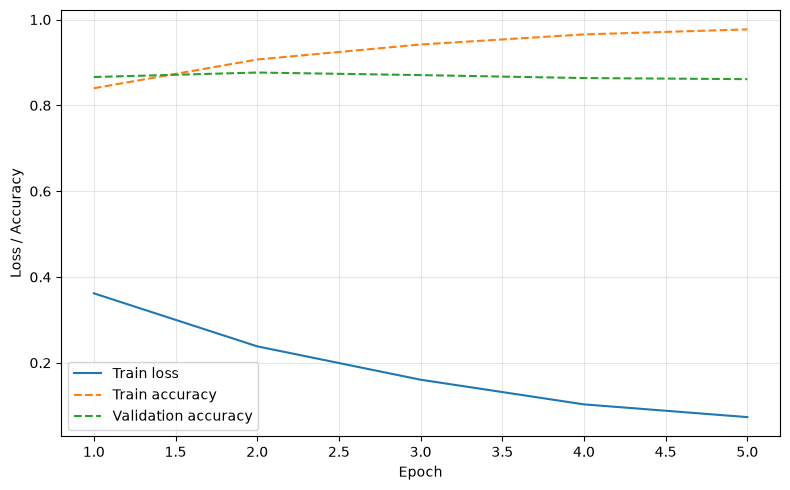

In [5]:
num_epochs, lr = 5, 2e-5

device = get_device()
net = BertClassifier(MODEL_NAME).to(device)

loss = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    net.parameters(),
    lr=lr,
)

# Create the text output before the plot to keep training status above it.
training_output = StringIO()
status_display = display(
    {"text/plain": f"Training on: {device}\nStarting the first epoch..."},
    raw=True, display_id=True,
)

with plt.ioff():
    fig, ax = plt.subplots(figsize=(8, 5))
plot_display = display(fig, display_id=True)
plt.close(fig)  # Avoid an extra automatic inline display.

def update_training_plot(history):
    latest = history[-1]
    message = (
        f"Epoch {latest['epoch']:02d} | "
        f"Train loss: {latest['train']['loss']:.3f} | "
        f"Train accuracy: {latest['train']['accuracy']:.3f} | "
        f"Val accuracy: {latest['val']['accuracy']:.3f}\n"
    )
    status_display.update(
        {"text/plain": message + training_output.getvalue()}, raw=True
    )
    plot_history(history, ax=ax)
    plot_display.update(fig)

with redirect_stdout(training_output):
    metric_history = train_model(
        model=net,
        train_loader=train_set,
        val_loader=val_set,
        loss_fn=loss,
        optimizer=optimizer,
        num_epochs=num_epochs,
        device=device,
        on_epoch_end=update_training_plot,
    )

last_metrics = metric_history[-1]
final_results = (
    f"Epoch {last_metrics['epoch']:02d} | "
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}\n"
)
status_display.update(
    {"text/plain": final_results + training_output.getvalue()}, raw=True
)

In [6]:
test_metrics = evaluate(
    model=net, 
    loader=test_set, 
    loss_fn=loss, 
    device=device)

print(f"Test loss:     {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4%}")
print(f"Test macro-F1: {test_metrics['macro_f1']:.4f}")

Test loss:     0.4687
Test accuracy: 87.6611%
Test macro-F1: 0.8738


## External tests

Run the cells below in this notebook's trained kernel. They evaluate all games in
`config.EXTERNAL_TEST_GAME_IDS` and the balanced 4,000-review IMDb movie test set.
Reuse the current trained model and its training-time text processing; no fitting
or vocabulary construction is performed here. IMDb uses sentiment labels
(0=negative, 1=positive), while Steam uses recommendation labels.


In [7]:
import importlib
import config

# Refresh dataset configuration without restarting the trained kernel.
EXTERNAL_TEST_GAME_IDS = importlib.reload(config).EXTERNAL_TEST_GAME_IDS

external_test_dfs = {}
for game, appid in EXTERNAL_TEST_GAME_IDS.items():
    external_df = pd.read_csv(
        Path("data/processed") / f"reviews_{game}_{appid}.csv",
        usecols=["review", "voted_up"],
        dtype={"review": "string", "voted_up": "boolean"},
    )
    external_df = external_df.dropna(subset=["review", "voted_up"]).copy()
    external_df["voted_up"] = external_df["voted_up"].astype("int64")
    external_test_dfs[game] = external_df
    print(f"{game}: {len(external_df)} external test reviews")

# IMDb sentiment labels already use 0=negative and 1=positive.
imdb_test_df = pd.read_csv(
    Path("data/processed/reviews_IMDB_test.csv"),
    usecols=["review", "voted_up"],
    dtype={"review": "string", "voted_up": "int64"},
)
imdb_test_df = imdb_test_df.dropna(subset=["review", "voted_up"]).copy()
external_test_dfs["IMDB"] = imdb_test_df
print(f"IMDB: {len(imdb_test_df)} external test reviews")

# collate_fn reuses the tokenizer and max_length configured for training.
external_test_loaders = {
    game: DataLoader(
        BertReviewDataset(external_df),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=0,
    )
    for game, external_df in external_test_dfs.items()
}


WARDOGS: 1826 external test reviews
SQUAD: 1464 external test reviews
CYBERPUNK_2077: 1558 external test reviews
PERSONA_5_ROYAL: 1527 external test reviews
BALDURS_GATE_3: 1598 external test reviews
DOTA2: 967 external test reviews
HOLLOW_KNIGHT_SILKSONG: 1516 external test reviews
STARDEW_VALLEY: 1445 external test reviews
ELDEN_RING: 1476 external test reviews
FORZA_HORIZON_6: 1532 external test reviews
AMONG_US: 1301 external test reviews
IMDB: 4000 external test reviews


In [8]:
# evaluate() switches net to evaluation mode and disables gradients.
# It does not update weights or use the training optimizer.
external_results = []
for game, external_loader in external_test_loaders.items():
    external_metrics = evaluate(
        model=net,
        loader=external_loader,
        loss_fn=loss,
        device=device,
    )
    external_results.append({
        "game": game,
        "samples": len(external_loader.dataset),
        "loss": external_metrics["loss"],
        "accuracy": external_metrics["accuracy"],
        "macro_f1": external_metrics["macro_f1"],
    })
    print(
        f"{game}: loss={external_metrics['loss']:.4f} | "
        f"accuracy={external_metrics['accuracy']:.4%} | "
        f"macro-F1={external_metrics['macro_f1']:.4f}"
    )

external_results = pd.DataFrame(external_results).set_index("game")
print("\nExternal test summary:")
print(external_results.to_string(float_format=lambda value: f"{value:.4f}"))


WARDOGS: loss=0.3216 | accuracy=90.7996% | macro-F1=0.9077
SQUAD: loss=0.4062 | accuracy=89.0710% | macro-F1=0.8854
CYBERPUNK_2077: loss=0.4172 | accuracy=88.2542% | macro-F1=0.8787
PERSONA_5_ROYAL: loss=0.4518 | accuracy=86.3785% | macro-F1=0.8612
BALDURS_GATE_3: loss=0.3540 | accuracy=90.0501% | macro-F1=0.8995
DOTA2: loss=0.6837 | accuracy=82.7301% | macro-F1=0.8173
HOLLOW_KNIGHT_SILKSONG: loss=0.4213 | accuracy=87.7309% | macro-F1=0.8748
STARDEW_VALLEY: loss=0.3347 | accuracy=89.9654% | macro-F1=0.8995
ELDEN_RING: loss=0.4441 | accuracy=87.6694% | macro-F1=0.8740
FORZA_HORIZON_6: loss=0.3615 | accuracy=90.0783% | macro-F1=0.8957
AMONG_US: loss=0.4551 | accuracy=87.0869% | macro-F1=0.8652
IMDB: loss=0.4315 | accuracy=86.9750% | macro-F1=0.8695

External test summary:
                        samples   loss  accuracy  macro_f1
game                                                      
WARDOGS                    1826 0.3216    0.9080    0.9077
SQUAD                      1464 0.4062    